# Git Fundamentals

**Git** is a **version control system**: it records snapshots of a project over time. With Git you can see who changed what and why, go back to any earlier state, and work on several changes in parallel without losing anything.

**After this lesson you can:**

1. Create a repository and explain the three areas: working directory, staging area, repository.
2. Record changes with `add` and `commit`, and inspect them with `status`, `log`, `diff` and `show`.
3. Undo changes safely with `restore`, `revert` and `reset`.
4. Explain how Git stores data (content-addressed objects).

Every command runs for real in a temporary folder.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

# Use a neutral identity and ignore your personal Git configuration, so the output is the same on every machine.
os.environ.update({"GIT_CONFIG_GLOBAL": os.devnull, "GIT_CONFIG_NOSYSTEM": "1",
                   "GIT_AUTHOR_NAME": "Ayse", "GIT_AUTHOR_EMAIL": "ayse@example.com",
                   "GIT_COMMITTER_NAME": "Ayse", "GIT_COMMITTER_EMAIL": "ayse@example.com"})
WORK = Path(tempfile.mkdtemp())

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def short(text: str) -> str:
    return text.replace(str(WORK), "<work>").replace(str(Path.cwd().parent), "<repo>")

def sh(cmd: str, cwd: Path = WORK, env: dict | None = None, quiet: bool = False) -> Output:
    """Run a shell command, print it and its output (temporary paths shortened)."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True, env={**os.environ, **(env or {})})
    out = short((r.stdout + r.stderr).strip())
    if not quiet:
        print(f"$ {short(cmd)}" + (f"\n{out}" if out else ""))
    return Output(r.stdout)

## 1. The Three Areas

| Area | What it is | Commands that move files into it |
| :--- | :--- | :--- |
| **Working directory** | the files you edit | your editor |
| **Staging area** (index) | the content of the *next* commit | `git add` |
| **Repository** | the history of commits, in the `.git` folder | `git commit` |

A **commit** is a snapshot of the whole project plus metadata: author, date, message and a pointer to its parent commit(s).

In [2]:
repo = WORK / "shop"
repo.mkdir()
sh("git init -b main", repo)
(repo / "prices.py").write_text("VAT = 0.20\n\ndef gross(net):\n    return net * (1 + VAT)\n")
sh("git status --short", repo)              # ?? = untracked
sh("git add prices.py && git status --short", repo)   # A = added to the staging area
sh('git commit -q -m "Add price calculation" && git log --oneline', repo)

$ git init -b main
Initialized empty Git repository in <work>/shop/.git/
$ git status --short
?? prices.py
$ git add prices.py && git status --short
A  prices.py
$ git commit -q -m "Add price calculation" && git log --oneline
6b4a9ac Add price calculation


## 2. Change, Compare, Commit

- `git diff` shows changes in the working directory that are **not staged**.
- `git diff --staged` shows what the next commit will contain.
- `git log` shows the history; `git show <commit>` shows one commit.

Good commit messages have a short summary line in the imperative mood ("Add discount rule", not "added stuff"), and an optional body that explains **why**.

In [3]:
(repo / "prices.py").write_text("VAT = 0.20\n\ndef gross(net, discount=0.0):\n    return round(net * (1 + VAT) * (1 - discount), 2)\n")
(repo / "README.md").write_text("# Shop\nPrice helpers.\n")
sh("git status --short", repo)
sh("git diff", repo)
sh("git add prices.py README.md", repo)
sh('git commit -q -m "Add discount parameter" -m "Marketing needs percentage discounts for campaigns."', repo)
sh("git log --stat --format='%h %s%n  author: %an, %ar'", repo)

$ git status --short
M prices.py
?? README.md
$ git diff
diff --git a/prices.py b/prices.py
index a12e663..605b5cf 100644
--- a/prices.py
+++ b/prices.py
@@ -1,4 +1,4 @@
 VAT = 0.20
 
-def gross(net):
-    return net * (1 + VAT)
+def gross(net, discount=0.0):
+    return round(net * (1 + VAT) * (1 - discount), 2)
$ git add prices.py README.md
$ git commit -q -m "Add discount parameter" -m "Marketing needs percentage discounts for campaigns."
$ git log --stat --format='%h %s%n  author: %an, %ar'
3cc1a47 Add discount parameter
  author: Ayse, 0 seconds ago

 README.md | 2 ++
 prices.py | 4 ++--
 2 files changed, 4 insertions(+), 2 deletions(-)
6b4a9ac Add price calculation
  author: Ayse, 0 seconds ago

 prices.py | 4 ++++
 1 file changed, 4 insertions(+)


## 3. Undo Changes Safely

| Situation | Command | Changes history? |
| :--- | :--- | :-: |
| discard edits in a file (not staged) | `git restore file` | no |
| unstage a file (keep the edits) | `git restore --staged file` | no |
| undo a commit that others may have | `git revert <commit>`: a **new** commit that reverses it | adds a commit |
| move the branch back (local, unpublished commits only) | `git reset --soft/--mixed/--hard <commit>` | yes |

Rule: never rewrite history that you already shared (pushed). Use `revert` for shared history.

In [4]:
(repo / "prices.py").write_text("BROKEN = True\n")
sh("git status --short && git restore prices.py && git status --short && head -1 prices.py", repo)

(repo / "prices.py").write_text((repo / "prices.py").read_text().replace("0.20", "0.18"))
sh('git commit -q -am "Lower VAT to 18%" && git log --oneline', repo)
sh('git revert --no-edit HEAD && git log --oneline && grep VAT prices.py | head -1', repo)

$ git status --short && git restore prices.py && git status --short && head -1 prices.py
M prices.py
VAT = 0.20
$ git commit -q -am "Lower VAT to 18%" && git log --oneline
e32dc09 Lower VAT to 18%
3cc1a47 Add discount parameter
6b4a9ac Add price calculation
$ git revert --no-edit HEAD && git log --oneline && grep VAT prices.py | head -1
[main bebfbab] Revert "Lower VAT to 18%"
 Date: Mon Nov 16 16:56:58 2026 +0300
 1 file changed, 1 insertion(+), 1 deletion(-)
bebfbab Revert "Lower VAT to 18%"
e32dc09 Lower VAT to 18%
3cc1a47 Add discount parameter
6b4a9ac Add price calculation
VAT = 0.20


`git revert` did not delete the "Lower VAT" commit. It added a new commit that undoes it, so the history stays truthful and safe to share.

## 4. How Git Stores Data

Git is a **content-addressed** store. Every file version is stored as a **blob** object whose name is the SHA-1 hash of its content (with a short header). A **tree** object lists file names and blob hashes; a **commit** object points to a tree and to its parent commit. Equal content always has the same hash, so Git stores it only once.

The cell computes the hash of a file in Python and compares it with Git's own result.

In [5]:
import hashlib

content = (repo / "README.md").read_bytes()
manual = hashlib.sha1(b"blob %d\0" % len(content) + content).hexdigest()
git_hash = sh("git hash-object README.md", repo, quiet=True).strip()
print("hash computed in Python:", manual)
print("hash computed by Git   :", git_hash, "| equal:", manual == git_hash)
sh("git cat-file -p HEAD", repo)                     # the commit object
sh("git cat-file -p 'HEAD^{tree}'", repo)            # the tree object
sh("git count-objects -v | head -2", repo)

hash computed in Python: 3420ab0fdef3bd892488e0667ccf0aae8294306b
hash computed by Git   : 3420ab0fdef3bd892488e0667ccf0aae8294306b | equal: True
$ git cat-file -p HEAD
tree 80fec1143bf91140c9cba9b6914bb97303a828b9
parent e32dc09db9b7dcdde92bd70dcc706f52b23cec52
author Ayse <ayse@example.com> 1794837418 +0300
committer Ayse <ayse@example.com> 1794837418 +0300

Revert "Lower VAT to 18%"

This reverts commit e32dc09db9b7dcdde92bd70dcc706f52b23cec52.
$ git cat-file -p 'HEAD^{tree}'
100644 blob 3420ab0fdef3bd892488e0667ccf0aae8294306b	README.md
100644 blob 605b5cf05fea24e58c7c6084e435d1b3120ab90f	prices.py
$ git count-objects -v | head -2
count: 11
size: 44


## 5. Real Data: the History of This Course

Git history is data. The cell reads the commit dates and change sizes of **this repository** with `git log` and plots them. (It reads only dates and line counts, not names.)

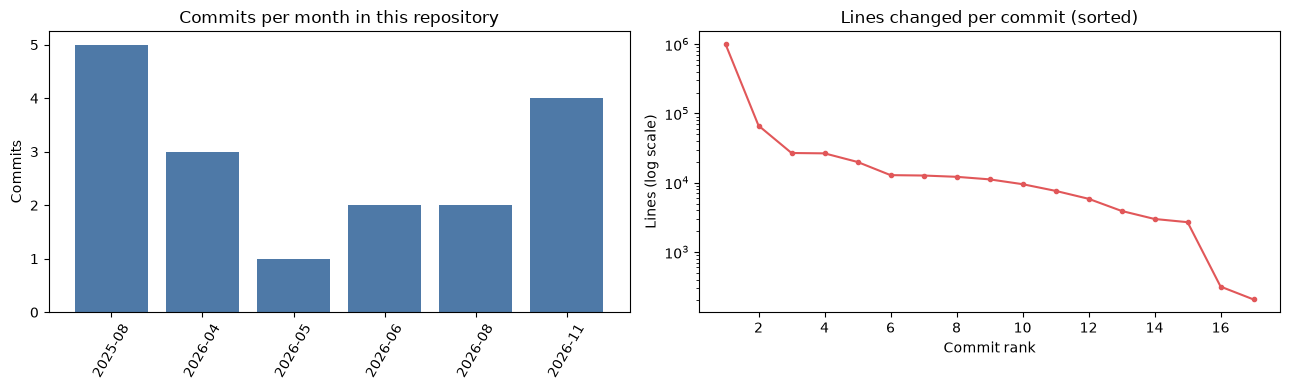

17 commits from 2025-08-09 to 2026-11-16; median change 11,173 lines, largest 1,002,927 lines


In [6]:
from collections import Counter
from datetime import datetime

import matplotlib.pyplot as plt

course = Path.cwd().parent
log = subprocess.run(["git", "log", "--format=@%ad", "--date=short", "--shortstat"], cwd=course,
                     capture_output=True, text=True).stdout
commits, current = [], None
for line in log.splitlines():
    if line.startswith("@"):
        current = {"date": datetime.strptime(line[1:], "%Y-%m-%d").date(), "changed": 0}
        commits.append(current)
    elif "changed" in line and current is not None:
        nums = [int(t) for t in line.replace(",", "").split() if t.isdigit()]
        current["changed"] = sum(nums[1:])          # insertions + deletions
by_month = Counter(c["date"].strftime("%Y-%m") for c in commits)
months = sorted(by_month)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(months, [by_month[m] for m in months], color="#4E79A7")
ax1.set(title="Commits per month in this repository", ylabel="Commits")
ax1.tick_params(axis="x", rotation=60)
sizes = sorted((c["changed"] for c in commits if c["changed"]), reverse=True)
ax2.plot(range(1, len(sizes) + 1), sizes, marker="o", ms=3, color="#E15759")
ax2.set(yscale="log", title="Lines changed per commit (sorted)", xlabel="Commit rank", ylabel="Lines (log scale)")
plt.tight_layout()
plt.show()
print(f"{len(commits)} commits from {commits[-1]['date']} to {commits[0]['date']}; "
      f"median change {sorted(sizes)[len(sizes) // 2]:,} lines, largest {sizes[0]:,} lines")

*Insight: Commit small, related changes with messages that explain why. A history of small commits is easy to review, easy to revert and easy to search with `git log` and `git bisect` (Lesson 03); one giant commit is none of these.*

## Real-World Use Case or Analogy

Git is like the **version history of a shared document**, but for a whole folder and with much more control. Every commit is a saved version with a note ("why I changed this"). You can compare any two versions, restore an old paragraph, or see who wrote a line and when (`git blame`).

Every software team uses Git. Data teams version code, SQL models (dbt, M11), notebooks and infrastructure definitions with it. Large data files and models go to separate tools that Git tracks by reference, such as DVC (M34) or Git LFS.